# Storyboard sequence generation


In [5]:
from pathlib import Path
import json
from PIL import Image, ImageOps, ImageDraw
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
panel_paths = '/content/drive/MyDrive/project/panels'
OUTPUT_DIR = '/content/drive/MyDrive/project/outputs'
method = 'controlnet_baseline'
seq_name = 'seq01'
out_dir = Path(OUTPUT_DIR) / method / seq_name

assert out_dir.is_dir(), f'Saved sequence folder not found: {out_dir}'
print('Reading saved sequence from:', out_dir)


Reading saved sequence from: /content/drive/MyDrive/project/outputs/controlnet_baseline/seq01


In [8]:
import os
from pathlib import Path
from PIL import Image

# 1. Resolve and check the panels folder
panels_dir = Path(panel_paths)
if not panels_dir.is_dir():
    raise FileNotFoundError(f"Panels folder not found: {panels_dir}")

# 2. Collect and sort image files (e.g., png, jpg, jpeg)
valid_extensions = {'.png', '.jpg', '.jpeg', '.webp'}
img_files = sorted([f for f in panels_dir.iterdir() if f.suffix.lower() in valid_extensions])
print(f"Found {len(img_files)} panel images in {panels_dir}")

# 3. Load original images
originals = []
for f in img_files:
    try:
        img = Image.open(f).convert('RGB')
        originals.append(img)
    except Exception as e:
        print(f"Warning: Failed to load {f.name} - {e}")
        originals.append(None)

# 4. Correct panel_paths to match the actual list of paths for the plotting code
panel_paths = [str(f) for f in img_files]

# 5. Initialize placeholders for frames and statuses (to match the originals for display purposes)
# Replace these placeholders with your actual frame sequences and generation status lists later
frames = [Image.new('RGB', (100, 100), color='gray') for _ in originals]
statuses = ['Placeholder' for _ in originals]


Found 6 panel images in /content/drive/MyDrive/project/panels


In [11]:
# Load actual generated frames and metadata from out_dir
import json

print(f"Scanning directory: {out_dir}")
# Gather actual generated image files (sorted to match the sequence, excluding conditioning files)
frame_extensions = {'.png', '.jpg', '.jpeg', '.webp'}
frame_files = sorted([
    f for f in out_dir.iterdir()
    if f.suffix.lower() in frame_extensions and "_cond" not in f.name
])

# Try to load corresponding images
real_frames = []
real_statuses = []

for i, panel_path in enumerate(panel_paths):
    # If there is a matching output frame file by sequence index
    if i < len(frame_files):
        try:
            img_path = frame_files[i]
            img = Image.open(img_path).convert('RGB')
            real_frames.append(img)
            real_statuses.append("Generated")
            print(f"Loaded frame {i+1}: {img_path.name}")
        except Exception as e:
            real_frames.append(Image.new('RGB', (100, 100), color='red'))
            real_statuses.append("Error loading")
    else:
        # Fallback if no generated output is found for this panel index yet
        real_frames.append(Image.new('RGB', (100, 100), color='gray'))
        real_statuses.append("Missing")

# Update active variables used by the display cell
frames = real_frames
statuses = real_statuses

Scanning directory: /content/drive/MyDrive/project/outputs/controlnet_baseline/seq01
Loaded frame 1: panel01.png
Loaded frame 2: panel02.png
Loaded frame 3: panel03.png
Loaded frame 4: panel04.png
Loaded frame 5: panel05.png
Loaded frame 6: panel06.png


In [13]:
import os
import glob

# --- Define a sequence: same character described the same way in every prompt ---
seq_name = 'seq01'
PANEL_DIR = '/content/drive/MyDrive/project/panels'
panel_files = sorted(glob.glob(os.path.join(PANEL_DIR, f'{seq_name}_panel*.png')))
CHAR = "a vampire"
SETTING = "blank background"

# 6 panels
actions = [
    "jelly vaporizes as camera pans up",
    "vampire hands slowly come into screen, close-up",
    "hands rapidly push vaporized blood upwards, close-up",
    "camera pans upto vampire's face, close-up",
    "vampire inhales jelly mist from right hand, close-up",
    "vampire inhales jelly mist from left hand, close-up",
]
prompts = [f"{CHAR}, {a}, {SETTING}" for a in actions][:len(panel_files)]

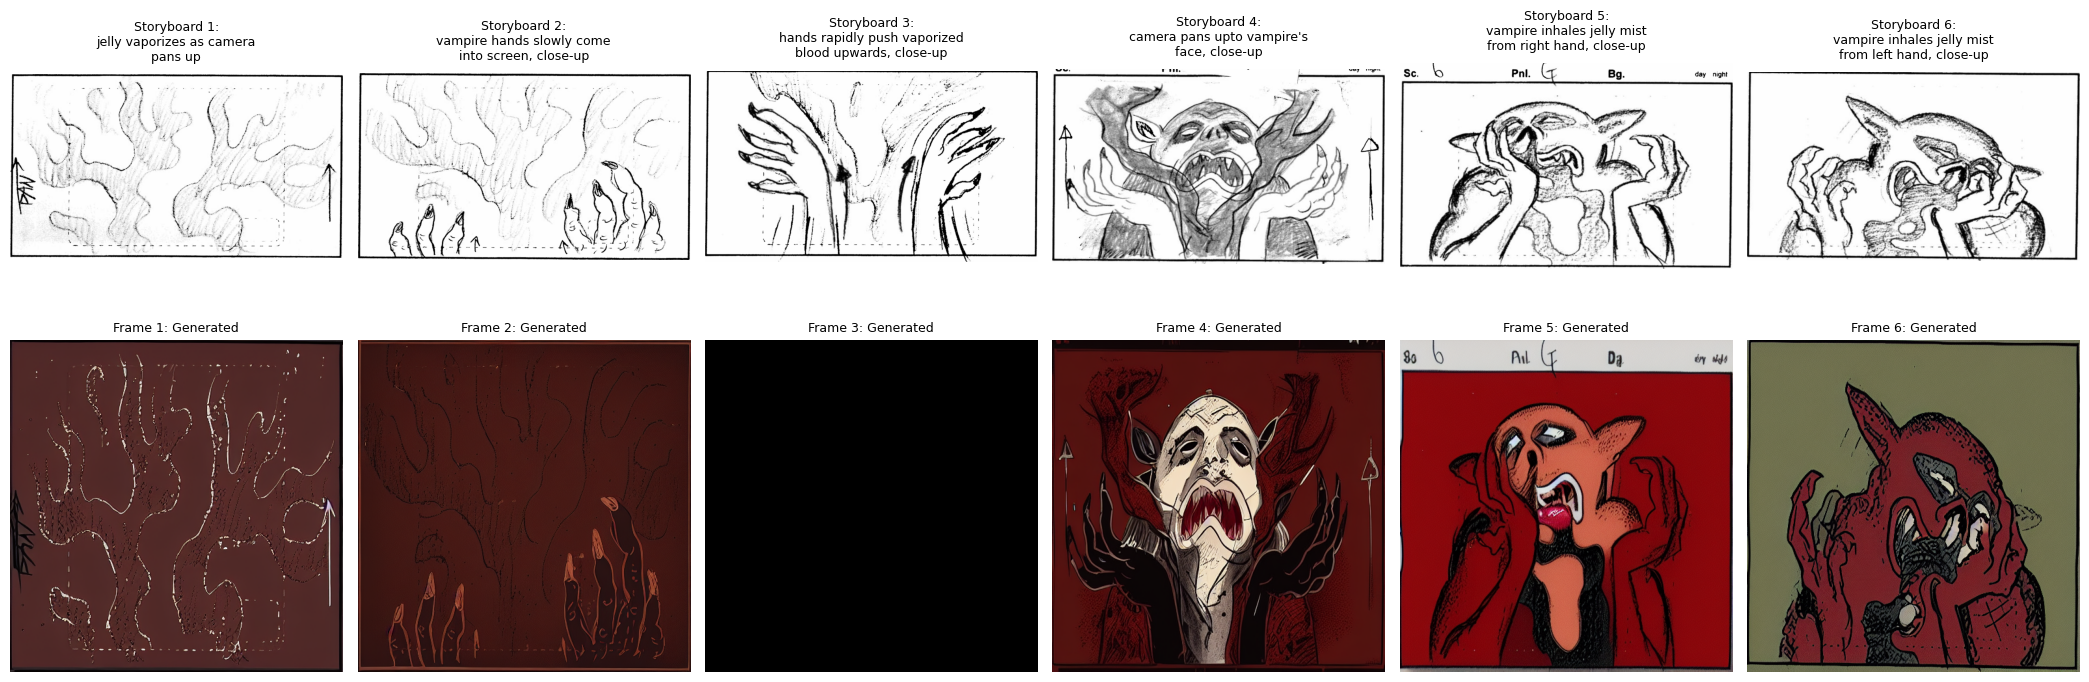

In [14]:
import textwrap

fig, axes = plt.subplots(2, len(panel_paths), figsize=(3.5 * len(panel_paths), 7.5))

if len(panel_paths) == 1:
    axes = axes.reshape(2, 1)

for column, (original, frame, status) in enumerate(zip(originals, frames, statuses)):
    # Get matching action/prompt description if available
    action_desc = ""
    if column < len(actions):
        action_desc = actions[column]

    wrapped_title = "\n".join(textwrap.wrap(action_desc, width=28))

    if original is not None:
        axes[0, column].imshow(original)
    else:
        axes[0, column].text(0.5, 0.5, 'Panel unreadable', ha='center', va='center')

    axes[0, column].set_title(f'Storyboard {column + 1}:\n{wrapped_title}', fontsize=9, pad=10)
    axes[1, column].imshow(frame)
    axes[1, column].set_title(f'Frame {column + 1}: {status}', fontsize=9)

    axes[0, column].axis('off')
    axes[1, column].axis('off')

plt.tight_layout()
plt.show()